# SVM, RANDOM FOREST AND ADABOOST

In [1]:
student_name='\u0905\u092D\u093F\u091C\u0940\u0924\u0020\u0915\u0941\u092E\u093E\u0930'
print("STUDENT NAME: ",student_name)

STUDENT NAME:  अभिजीत कुमार


In [2]:
submited_to='\u0935\u0948\u0936\u093E\u0932\u0940\u0020\u0907\u0902\u0917\u0933\u0947'
print("SUBMITED TO: ",submited_to)

SUBMITED TO:  वैशाली इंगळे


## IMPORTING LIBRARIES

In [3]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier, AdaBoostClassifier
from sklearn.model_selection import cross_val_score, GridSearchCV

from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,classification_report,confusion_matrix

#### LOADING DATASET

In [4]:
columns = ["buying_price","maintenance_cost","number_of_doors","number_of_persons","lug_boot","safety","decision"]

df = pd.read_csv("car_evaluation.csv",header=None,names=columns)

print("Number of samples:", df.shape[0])
print("Number of features:", df.shape[1])
display(df.head(5))


Number of samples: 1728
Number of features: 7


,buying_price,maintenance_cost,number_of_doors,number_of_persons,lug_boot,safety,decision
0,vhigh,vhigh,2,2,small,low,unacc
1,vhigh,vhigh,2,2,small,med,unacc
2,vhigh,vhigh,2,2,small,high,unacc
3,vhigh,vhigh,2,2,med,low,unacc
4,vhigh,vhigh,2,2,med,med,unacc


#### DATA ANALYSIS

In [5]:
print("Missing values:")
print(df.isnull().sum())

if(df.duplicated().sum()==0):
  print("\nNo duplicate rows present.")
else:
  print("\nDuplicate rows:", df.duplicated().sum())


Missing values:
buying_price         0
maintenance_cost     0
number_of_doors      0
number_of_persons    0
lug_boot             0
safety               0
decision             0
dtype: int64

No duplicate rows present.


In [6]:
print("\nUnique values in each column:")
for column in df.columns:
    print(column, ":", df[column].unique())


Unique values in each column:
buying_price : <StringArray>
['vhigh', 'high', 'med', 'low']
Length: 4, dtype: str
maintenance_cost : <StringArray>
['vhigh', 'high', 'med', 'low']
Length: 4, dtype: str
number_of_doors : <StringArray>
['2', '3', '4', '5more']
Length: 4, dtype: str
number_of_persons : <StringArray>
['2', '4', 'more']
Length: 3, dtype: str
lug_boot : <StringArray>
['small', 'med', 'big']
Length: 3, dtype: str
safety : <StringArray>
['low', 'med', 'high']
Length: 3, dtype: str
decision : <StringArray>
['unacc', 'acc', 'vgood', 'good']
Length: 4, dtype: str


In [7]:
print("\nDecision class distribution:")
print(df["decision"].value_counts())


Decision class distribution:
decision
unacc    1210
acc       384
good       69
vgood      65
Name: count, dtype: int64


#### DEPENDENT AND INDEPENEDENT FEATURES

In [8]:
# Separate input features and target
X = df.drop("decision", axis=1)
y = df["decision"]

#### ONEHOT ENCODING AND LABEL ENCODER

In [9]:
# Convert categorical input features into numeric columns
X = pd.get_dummies(X, dtype=int)

# Encode target classes into numbers
encoder = LabelEncoder()
y = encoder.fit_transform(y)

print("Encoded feature shape:", X.shape)
print("Target classes:", encoder.classes_)
display(X.head())

Encoded feature shape: (1728, 21)
Target classes: ['acc' 'good' 'unacc' 'vgood']


,buying_price_high,buying_price_low,buying_price_med,buying_price_vhigh,maintenance_cost_high,maintenance_cost_low,maintenance_cost_med,maintenance_cost_vhigh,number_of_doors_2,number_of_doors_3,...,number_of_doors_5more,number_of_persons_2,number_of_persons_4,number_of_persons_more,lug_boot_big,lug_boot_med,lug_boot_small,safety_high,safety_low,safety_med
0,0,0,0,1,0,0,0,1,1,0,...,0,1,0,0,0,0,1,0,1,0
1,0,0,0,1,0,0,0,1,1,0,...,0,1,0,0,0,0,1,0,0,1
2,0,0,0,1,0,0,0,1,1,0,...,0,1,0,0,0,0,1,1,0,0
3,0,0,0,1,0,0,0,1,1,0,...,0,1,0,0,0,1,0,0,1,0
4,0,0,0,1,0,0,0,1,1,0,...,0,1,0,0,0,1,0,0,0,1


#### TRAIN TEST SPLIT

In [10]:
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])

print("Training target distribution:")
print(pd.Series(y_train).value_counts())

print("\nTesting target distribution:")
print(pd.Series(y_test).value_counts())

Training samples: 1382
Testing samples: 346
Training target distribution:
2    968
0    307
1     55
3     52
Name: count, dtype: int64

Testing target distribution:
2    242
0     77
1     14
3     13
Name: count, dtype: int64


#### MODEL TRAINING

In [11]:
# Initialize models with default hyperparameters
models = {
    "SVM": SVC(),
    "Random Forest": RandomForestClassifier(random_state=42),
    "AdaBoost": AdaBoostClassifier(random_state=42)
}

# Train each model
for name, model in models.items():
    model.fit(X_train, y_train)
    print(name, "training completed")

SVM training completed
Random Forest training completed
AdaBoost training completed


In [12]:
results = []

for name, model in models.items():

    # Predict on testing data
    test_pred = model.predict(X_test)

    # Calculate evaluation metrics
    accuracy = accuracy_score(y_test, test_pred)
    precision = precision_score(y_test, test_pred, average='weighted', zero_division=0)
    recall = recall_score(y_test, test_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_test, test_pred, average='weighted', zero_division=0)

    # Store results
    results.append({
        "Model": name,
        "Accuracy": accuracy,
        "Precision": precision,
        "Recall": recall,
        "F1-Score": f1
    })

# Convert results into a DataFrame
results_df = pd.DataFrame(results)

# Display comparison table
print(results_df.round(4))

           Model  Accuracy  Precision  Recall  F1-Score
0            SVM    0.9740     0.9752  0.9740    0.9742
1  Random Forest    0.9682     0.9688  0.9682    0.9678
2       AdaBoost    0.8439     0.8554  0.8439    0.8394


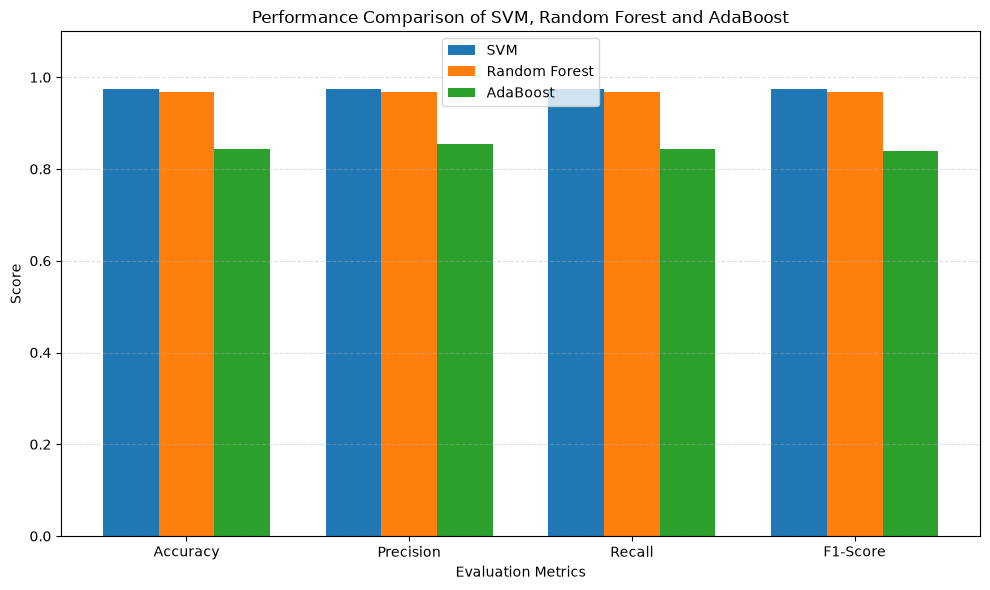

In [13]:
# Define metrics and model positions
metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]

x = np.arange(len(metrics))
width = 0.25

# Create figure
plt.figure(figsize=(10, 6))

# Plot each model
for i, row in results_df.iterrows():
    values = [row[metric] for metric in metrics]

    plt.bar(x + (i - 1) * width,values,width,label=row["Model"])

# Add labels and title
plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
plt.title("Performance Comparison of SVM, Random Forest and AdaBoost")

plt.xticks(x, metrics)
plt.ylim(0, 1.1)
plt.legend()
plt.grid(axis="y", linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

In [14]:
cv_results = []

for name, model in models.items():

    scores = cross_val_score(model, X_train, y_train, cv=5, scoring="accuracy")

    cv_results.append({"Model": name,"CV Accuracy": scores.mean(),"CV Standard Deviation": scores.std()})

    print("\n", name)
    print("Fold accuracies:", scores.round(4))
    print("Mean CV Accuracy:", round(scores.mean() * 100, 2), "%")

cv_df = pd.DataFrame(cv_results)
display(cv_df)


 SVM
Fold accuracies: [0.9675 0.9422 0.9529 0.9601 0.9529]
Mean CV Accuracy: 95.51 %

 Random Forest
Fold accuracies: [0.9567 0.9422 0.9493 0.9493 0.9275]
Mean CV Accuracy: 94.5 %

 AdaBoost
Fold accuracies: [0.8556 0.8087 0.8152 0.8587 0.8514]
Mean CV Accuracy: 83.79 %


,Model,CV Accuracy,CV Standard Deviation
0,SVM,0.955138,0.008421
1,Random Forest,0.945001,0.009855
2,AdaBoost,0.837924,0.021440


#### HYPERPARAMETER TUNING

In [15]:
# 1. Define parameter grids
param_grids = {
    "SVM": {
        "C": [0.1, 1, 10],
        "kernel": ["linear", "rbf"],
        "gamma": ["scale", "auto"]
    },

    "Random Forest": {
        "n_estimators": [50, 100, 200],
        "max_depth": [None, 10, 20],
        "min_samples_split": [2, 5]
    },

    "AdaBoost": {
        "n_estimators": [50, 100, 200],
        "learning_rate": [0.01, 0.1, 1.0]
    }
}

# 2. Perform Grid Search CV


optimized_models = {}

for name, model in models.items():

    grid = GridSearchCV(
        model 
        param_grids[name],
        cv=5,
        scoring="accuracy",
        n_jobs=-1
    )

    grid.fit(X_train, y_train)

    optimized_models[name] = grid.best_estimator_

    print("\n", name)
    print("Best Parameters:", grid.best_params_)
    print("Best CV Accuracy:", round(grid.best_score_ * 100, 2), "%")


# 3. Evaluate optimized models
results = {}

for name, model in optimized_models.items():

    y_pred = model.predict(X_test)

    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(
        y_test, y_pred, average="weighted", zero_division=0
    )
    recall = recall_score(
        y_test, y_pred, average="weighted", zero_division=0
    )
    f1 = f1_score(
        y_test, y_pred, average="weighted", zero_division=0
    )

    results[name] = [accuracy, precision, recall, f1]

    print("\n", name)
    print("Testing Accuracy:", round(accuracy * 100, 2), "%")
    print("Precision:", round(precision, 4))
    print("Recall:", round(recall, 4))
    print("F1-Score:", round(f1, 4))




 SVM
Best Parameters: {'C': 10, 'gamma': 'scale', 'kernel': 'rbf'}
Best CV Accuracy: 99.78 %

 Random Forest
Best Parameters: {'max_depth': 10, 'min_samples_split': 2, 'n_estimators': 200}
Best CV Accuracy: 94.79 %

 AdaBoost
Best Parameters: {'learning_rate': 1.0, 'n_estimators': 200}
Best CV Accuracy: 86.04 %

 SVM
Testing Accuracy: 100.0 %
Precision: 1.0
Recall: 1.0
F1-Score: 1.0

 Random Forest
Testing Accuracy: 95.38 %
Precision: 0.9565
Recall: 0.9538
F1-Score: 0.953

 AdaBoost
Testing Accuracy: 83.24 %
Precision: 0.8432
Recall: 0.8324
F1-Score: 0.8304


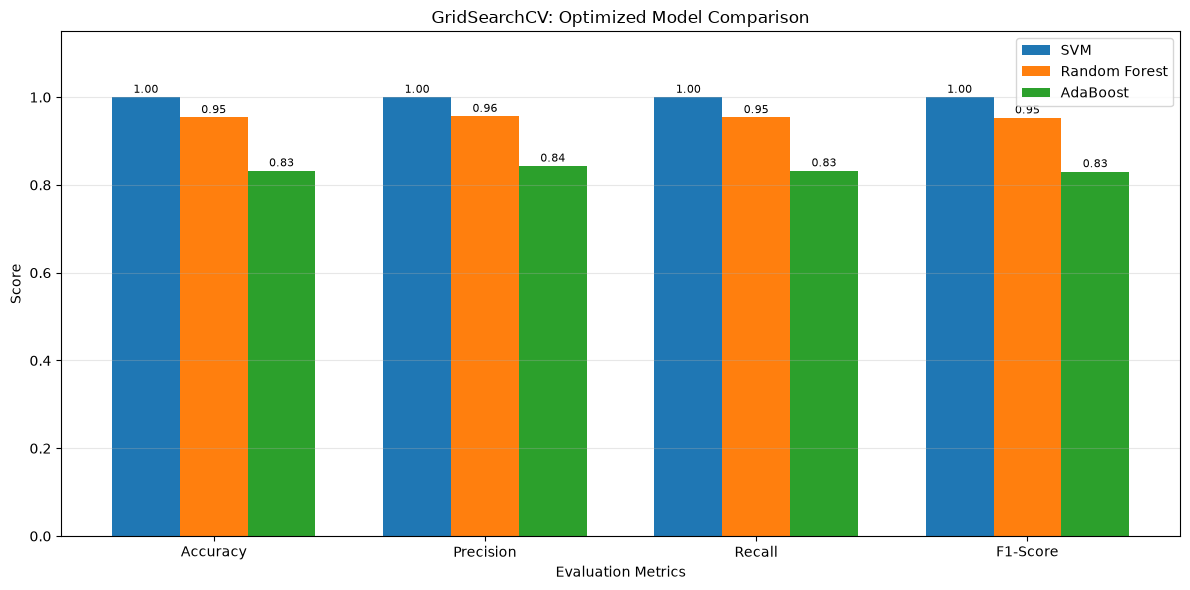

In [16]:
# 4. Plot all metrics in one graph
metrics = ["Accuracy", "Precision", "Recall", "F1-Score"]
x = np.arange(len(metrics))
width = 0.25

plt.figure(figsize=(12, 6))

for i, (name, scores) in enumerate(results.items()):
    bars = plt.bar(x + i * width, scores, width, label=name)

    for bar in bars:
        plt.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + 0.01,
            f"{bar.get_height():.2f}",
            ha="center",
            fontsize=8
        )

plt.xlabel("Evaluation Metrics")
plt.ylabel("Score")
plt.title("GridSearchCV: Optimized Model Comparison")
plt.xticks(x + width, metrics)
plt.ylim(0, 1.15)
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()